In [1]:
import cv2
import mediapipe as mp
import numpy as np
import time
import matplotlib.pyplot as plt
from collections import deque

In [2]:
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

model_path = "../models/face_landmarker.task"

base_options = python.BaseOptions(
    model_asset_path=model_path
)

options = vision.FaceLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.VIDEO,
    num_faces=1
)

detector = vision.FaceLandmarker.create_from_options(options)

print("Video Face Landmarker initialized!")

Video Face Landmarker initialized!


In [3]:
LEFT_EYE = [33, 160, 158, 133, 153, 144]

RIGHT_EYE = [362, 385, 387, 263, 373, 380]

In [4]:
def euclidean_distance(p1, p2):
    return np.linalg.norm(p1 - p2)


def get_eye_coordinates(landmarks, indices, width, height):

    points = []

    for index in indices:

        x = int(landmarks[index].x * width)
        y = int(landmarks[index].y * height)

        points.append([x, y])

    return np.array(points)


def calculate_ear(eye):

    A = euclidean_distance(eye[1], eye[5])
    B = euclidean_distance(eye[2], eye[4])
    C = euclidean_distance(eye[0], eye[3])

    return (A + B) / (2.0 * C)

In [5]:
EAR_THRESHOLD = 0.20

MIN_BLINK_DURATION = 0.08
MAX_BLINK_DURATION = 0.40

DROWSY_DURATION = 1.5

blink_count = 0

eye_closed = False
eye_closed_start = None

blink_durations = deque(maxlen=100)
ear_history = deque(maxlen=150)

start_time = time.monotonic()

print("Parameters configured!")

Parameters configured!


In [6]:
cap = cv2.VideoCapture(0)

if not cap.isOpened():
    raise RuntimeError("Unable to access webcam")

fps = cap.get(cv2.CAP_PROP_FPS)

print("Camera FPS:", fps)

Camera FPS: 30.0


In [ ]:

import time
import cv2

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    raise RuntimeError("Camera could not be opened")

blink_count = 0
eye_closed = False
eye_closed_start = None

start_time = time.monotonic()

# Maximum webcam runtime: 30 seconds
MAX_RUNTIME = 30

try:

    while True:

        # Automatic timeout
        if time.monotonic() - start_time > MAX_RUNTIME:
            print("Maximum runtime reached")
            break

        ret, frame = cap.read()

        if not ret:
            print("Frame capture failed")
            break

        height, width, _ = frame.shape

        rgb_frame = cv2.cvtColor(
            frame, cv2.COLOR_BGR2RGB
        )

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb_frame
        )

        timestamp_ms = int(
            (time.monotonic() - start_time) * 1000
        )

        results = detector.detect_for_video(
            mp_image,
            timestamp_ms
        )

        avg_ear = None

        if results.face_landmarks:

            landmarks = results.face_landmarks[0]

            left_eye = get_eye_coordinates(
                landmarks, LEFT_EYE, width, height
            )

            right_eye = get_eye_coordinates(
                landmarks, RIGHT_EYE, width, height
            )

            left_ear = calculate_ear(left_eye)
            right_ear = calculate_ear(right_eye)

            avg_ear = (left_ear + right_ear) / 2

            ear_history.append(avg_ear)

            if avg_ear < EAR_THRESHOLD:

                if not eye_closed:
                    eye_closed = True
                    eye_closed_start = time.monotonic()

            else:

                if eye_closed:

                    duration = (
                        time.monotonic() - eye_closed_start
                    )

                    if MIN_BLINK_DURATION <= duration <= MAX_BLINK_DURATION:
                        blink_count += 1
                        blink_durations.append(duration)

                    eye_closed = False
                    eye_closed_start = None

            for eye in [left_eye, right_eye]:
                for point in eye:
                    cv2.circle(
                        frame,
                        tuple(point),
                        2,
                        (0, 255, 0),
                        -1
                    )

        cv2.putText(
            frame,
            f"Blinks: {blink_count}",
            (30, 50),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (0, 255, 0),
            2
        )

        cv2.imshow("FocusAI", frame)

        # Q key or ESC key
        key = cv2.waitKey(1) & 0xFF

        if key == ord('q') or key == 27:
            print("Exit key detected")
            break

finally:

    cap.release()
    cv2.destroyAllWindows()

print("Camera released!")
print("Total blinks:", blink_count)


In [8]:
session_duration = time.monotonic() - start_time

blink_rate = (
    blink_count / session_duration
) * 60 if session_duration > 0 else 0

print("Session duration:", round(session_duration, 2), "seconds")
print("Total blinks:", blink_count)
print("Blink rate:", round(blink_rate, 2), "blinks/minute")

if blink_durations:
    print(
        "Average blink duration:",
        round(np.mean(blink_durations), 3),
        "seconds"
    )

Session duration: 131.89 seconds
Total blinks: 26
Blink rate: 11.83 blinks/minute
Average blink duration: 0.2 seconds


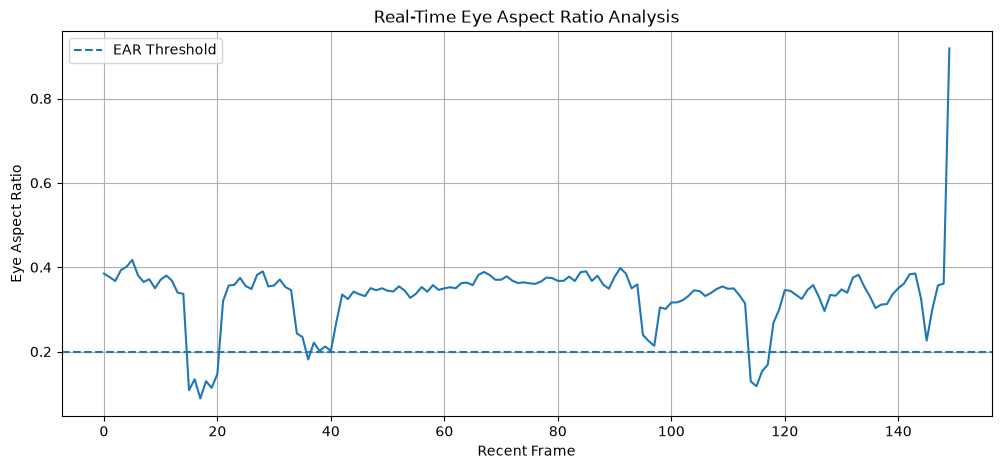

In [9]:
plt.figure(figsize=(12, 5))

plt.plot(list(ear_history))

plt.axhline(
    y=EAR_THRESHOLD,
    linestyle="--",
    label="EAR Threshold"
)

plt.xlabel("Recent Frame")
plt.ylabel("Eye Aspect Ratio")
plt.title("Real-Time Eye Aspect Ratio Analysis")

plt.legend()
plt.grid()
plt.show()

In [10]:
!git init
!git add README.md
!git commit -m "first commit"
!git branch -M main
!git remote add origin https://github.com/triyanjha04-dev/Focus-ai.git
!git push -u origin main

Initialized empty Git repository in E:/focusai/FocusAI/notebooks/.git/


fatal: pathspec 'README.md' did not match any files


On branch master

Initial commit

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.ipynb_checkpoints/
	01_Webcam_and_OpenCV.ipynb
	02_Facial_Landmark_Detection.ipynb
	03_Eye_Tracking.ipynb
	04_Head_Pose_Estimation.ipynb
	05_Gaze_Estimation.ipynb
	06_Attention_Feature_Extraction.ipynb
	07_LSTM_Classification.ipynb
	08_Model_Evaluation.ipynb

nothing added to commit but untracked files present (use "git add" to track)


error: src refspec main does not match any
error: failed to push some refs to 'https://github.com/triyanjha04-dev/Focus-ai.git'


In [11]:
%cd E:/focusai/FocusAI
!dir
!rmdir /s /q notebooks\.git


E:\focusai\FocusAI
 Volume in drive E is New Volume
 Volume Serial Number is CC39-3C59

 Directory of E:\focusai\FocusAI

11/13/2026  11:30 PM    <DIR>          .
11/13/2026  11:30 PM    <DIR>          ..
11/13/2026  11:30 PM    <DIR>          data
11/14/2026  02:54 PM    <DIR>          models
11/14/2026  05:08 PM    <DIR>          notebooks
11/13/2026  11:30 PM    <DIR>          outputs
11/13/2026  11:30 PM                85 README.md
               1 File(s)             85 bytes
               6 Dir(s)  27,179,384,832 bytes free


In [ ]:
!git init
!git branch -M main
!git add .
!git commit -m "Initial commit :FocusAI project"
!git remote ad